In [35]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv("/content/placement.csv")

In [3]:
df.head()

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


In [ ]:
#even = ((n/2)+(n/2))/2

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df['resume_score'].describe()

,resume_score
count,100.000000
mean,6.930500
std,0.979608
min,4.950000
25%,6.190000
50%,7.055000
75%,7.640000
max,9.060000


<Axes: xlabel='resume_score'>

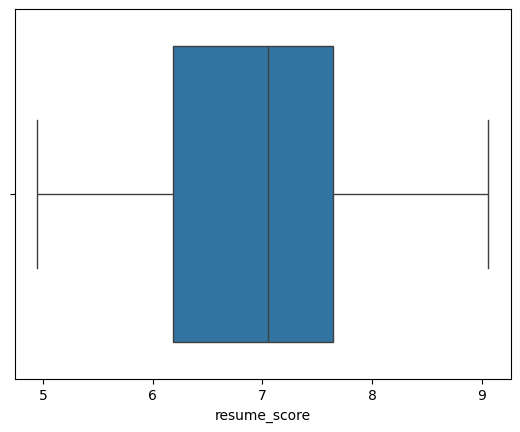

In [7]:
sns.boxplot(x = df['resume_score'])

In [9]:
# finding the IQR
precentile25 = df['resume_score'].quantile(0.25)
precentile75 = df['resume_score'].quantile(0.75)


In [10]:
precentile25

np.float64(6.19)

In [11]:
precentile75

np.float64(7.64)

In [13]:
IQR = precentile25 - precentile75
IQR

np.float64(-1.4499999999999993)

In [14]:
upper_limit =  precentile75  + 1.5*IQR
upper_limit

np.float64(5.465000000000001)

In [16]:
lower_limit =  precentile75  -1.5*IQR
lower_limit

np.float64(9.814999999999998)

In [17]:
# finding our outliers

In [18]:
df[df['resume_score']>upper_limit]

,cgpa,resume_score,placed
0,8.14,6.52,1
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
5,8.77,6.19,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


In [19]:
df[df['resume_score']<lower_limit]


,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


In [ ]:
#Triersmming ---> 4(Lower)....1 , upper(25).....(50)----> here 1,50 are outli
# lower(4) <----> upper(25)mid data
capping ---> 4(lower).....1 , upper(25) .... (50) _---> capping lower

In [20]:
#trimmig (outlier removing technique 1)

In [22]:
newdf = [df[df['resume_score']<upper_limit]]

In [23]:
#newdf

In [24]:
#comparison

AttributeError: module 'seaborn' has no attribute 'subplot'

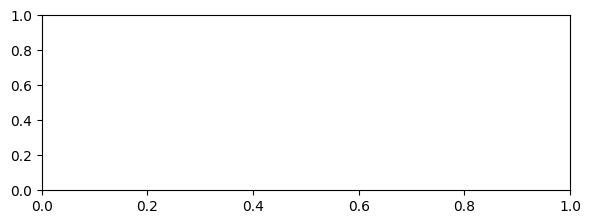

In [26]:
plt.figure(figsize=(15,5))
plt.subplot(222)
sns.subplot(x = df['resume_score'])
plt.subplot(224)
sns.subplot(x = newdf['resume_score'])
plt.show()

In [27]:
# capping(outlier removing technique 2)

In [32]:
new_df_Cap = df.copy()

In [ ]:
# min = 5 , max 15
# min 4,3,1
# max= 20 ,30 , 50

# updated_min_value=1
# updated_max_value=50

In [36]:
new_df_Cap['resume_score']=np.where(
    new_df_Cap['resume_score']>upper_limit,
    upper_limit,

    np.where(
        new_df_Cap['resume_score']< lower_limit,
        lower_limit,
        new_df_Cap['resume_score'])
)